# 12 — Separating the trend from the noise, per regime

`scripts/decompose.py`. Two questions:
1. How is the charge variance spread over time scales in each regime, and which scales does the laser / camera
   share?
2. Which causal filter gives the best level (trend), so that the jitter models see the cleanest jitter?

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parents[1] if Path.cwd().name == "adnan" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from regimes import load, score, REGIMES, NOISE_FLOOR_PCT
R = ROOT / "results"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
REG_COL = {"low": "tab:blue", "high_rep": "tab:orange", "high_nonrep": "tab:green"}
SEG_ORDER = [0, 3, 4, 5, 1, 6, 7]
def segcols(df):
    return [c for c in SEG_ORDER if c in set(df.columns.get_level_values(-1))]

## 1. Spectra without gap filling

About 15 % of the shots are not good (dropouts, frozen readings). Filling them before an FFT invents structure, so
the spectra use the Lomb–Scargle periodogram on the good shots only (training part).

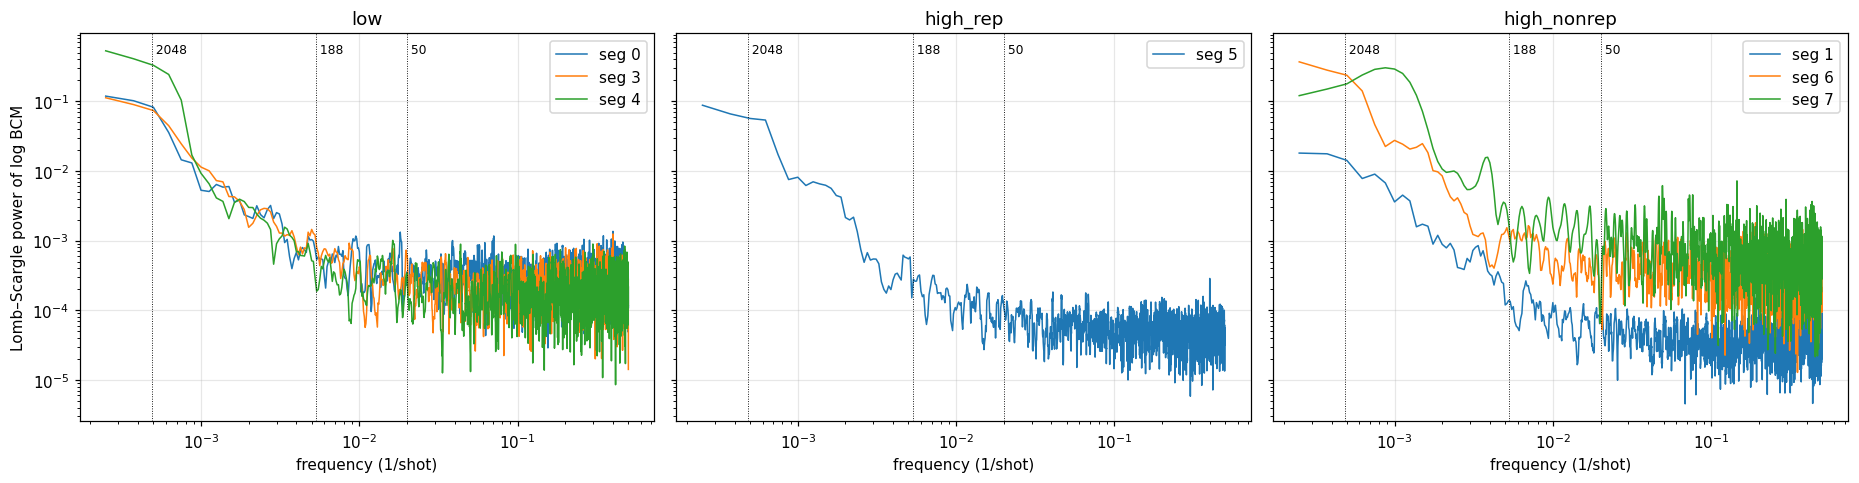

In [2]:
from scipy.signal import lombscargle, welch
segs, names = load(R.parent / "results/datasets", robust=5)
f = np.linspace(1 / 4000, 0.5, 4000); w = 2 * np.pi * f
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, (reg, ss) in zip(axes, REGIMES.items()):
    for s in ss:
        g = segs[s]
        if g["n"] < 1000: continue
        m = g["fit"]; t = np.flatnonzero(m).astype(float); x = g["logy"][m]
        p = lombscargle(t, x - x.mean(), w, normalize=True)
        ax.loglog(f, pd.Series(p).rolling(5, center=True, min_periods=1).mean(), label=f"seg {s}", lw=1)
    for per in (2048, 188, 50):
        ax.axvline(1 / per, color="k", lw=0.6, ls=":"); ax.text(1 / per, ax.get_ylim()[1] if False else 0.5, f" {per}", fontsize=8)
    ax.set_title(reg); ax.set_xlabel("frequency (1/shot)"); ax.legend()
axes[0].set_ylabel("Lomb–Scargle power of log BCM")
fig.tight_layout()

In [3]:
def peaks(t, x, n=4):
    p = lombscargle(t, x - x.mean(), w, normalize=True); out = []
    for i in np.argsort(p)[::-1]:
        if all(abs(f[i] - q) > 0.004 for q in out): out.append(f[i])
        if len(out) == n: break
    return [round(1 / q, 1) for q in out]
rows = []
for s in (5, 1, 6, 0, 3):
    g = segs[s]; m = g["fit"]; t = np.flatnonzero(m).astype(float)
    for lab, x in (("BCM", g["logy"][m]), ("lab laser", g["X"][m, names.index("lab_laser_power")]),
                   ("camera", g["X"][m, names.index("BTV_intensity")])):
        ok = np.isfinite(x)
        rows.append({"segment": s, "signal": lab, "strongest periods (shots)": peaks(t[ok], x[ok])})
pd.DataFrame(rows)

,segment,signal,strongest periods (shots)
0,5,BCM,"[2666.9, 205.2, 24.6, 14.6]"
1,5,lab laser,"[2666.9, 205.2, 95.3, 2.5]"
2,5,camera,"[2666.9, 205.2, 95.3, 24.6]"
3,1,BCM,"[4000.0, 216.3, 5.0, 2.5]"
4,1,lab laser,"[4000.0, 216.3, 2.5, 45.2]"
5,1,camera,"[4000.0, 216.3, 22.7, 77.7]"
6,6,BCM,"[4000.0, 2.5, 2.4, 3.0]"
7,6,lab laser,"[2666.9, 2.5, 5.2, 156.9]"
8,6,camera,"[2666.9, 138.0, 2.5, 2.8]"
9,0,BCM,"[4000.0, 2.5, 2.7, 200.0]"


**Reading.**
- **Seg 5 (repetitive):** the 1500–3000-shot sawtooth, plus a ~188-shot cycle (≈ 3.8 min) shared by the charge, the
  lab laser and the camera: laser-driven. Seg 1 has a similar ~200-shot cycle.
- **2.5 shots everywhere:** an artefact of the row grid. Rows are not evenly spaced pulses (the acquisition skips
  pulses), so this is not beam physics.
- Notebook 14 tests whether the ~190-shot cycle helps forecasting: it does not, its phase does not hold.

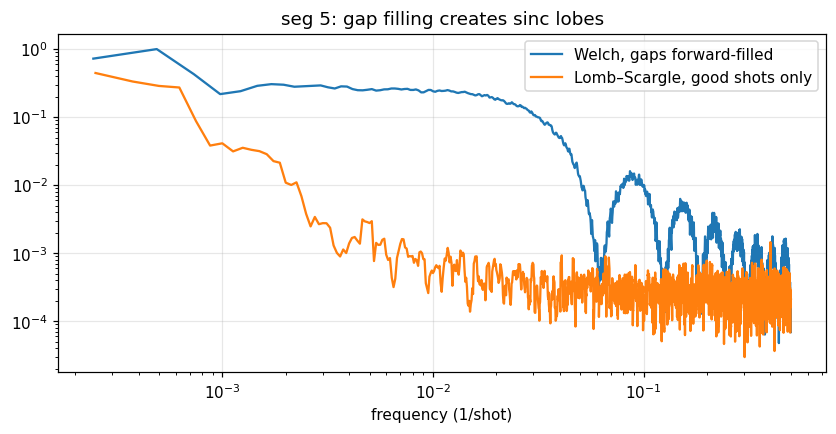

In [4]:
g = segs[5]; m = g["fit"]
y = pd.Series(np.where(g["good"], g["logy"], np.nan))[: int(0.9 * g["n"])].ffill().bfill().to_numpy()
fw, pw = welch(y - y.mean(), nperseg=4096)
t = np.flatnonzero(m).astype(float); pl = lombscargle(t, g["logy"][m] - g["logy"][m].mean(), w, normalize=True)
fig, ax = plt.subplots(figsize=(9, 4))
ax.loglog(fw[1:], pw[1:] / pw[1:].max(), label="Welch, gaps forward-filled")
ax.loglog(f, pd.Series(pl).rolling(5, center=True, min_periods=1).mean() / pl.max(), label="Lomb–Scargle, good shots only")
ax.set_xlabel("frequency (1/shot)"); ax.set_title("seg 5: gap filling creates sinc lobes"); ax.legend()

**Trap:** with gaps forward-filled, the Welch spectrum of seg 5 shows sinc-shaped lobes (nulls near 1/15, 2/15)
that look like a 15-shot boxcar. They come from the filled gaps, not the beam.

## 2. Causal level filters

Each filter estimates the level of shot n from the good shots before n only. All 36 settings pass a leak test
(changing the future never changes a past level). Families: moving average, EMA (= steady-state Kalman local level),
trailing median, Holt (local linear trend, the causal counterpart of a Hodrick–Prescott trend), outlier-robust EMA
(updates clipped at 3 robust sigmas), change-point reset (the hybrid forecaster's mean since the last level change).

Chosen on the **validation** block by the error of a ridge on the resulting jitter (robust preparation).

,regime,filter,param,val_ridge_mae_pct,test_ridge_mae_pct,val_jitter_acf1,val_corr_camera,val_corr_lab
28,high_nonrep,robust_ema,hl=25,1.396,1.440,0.110,0.730,0.325
17,high_nonrep,holt,"a=0.05,b=0.001",1.417,1.449,0.080,0.718,0.305
9,high_nonrep,ema,hl=10,1.420,1.458,0.064,0.717,0.293
34,high_nonrep,sma,k=50,1.431,1.475,0.117,0.722,0.334
25,high_nonrep,median,k=51,1.469,1.500,0.129,0.723,0.338
5,high_nonrep,cp_reset,"z=6,w=50",1.986,2.003,0.117,0.698,0.334
64,high_rep,robust_ema,hl=25,1.896,0.990,0.185,0.576,0.217
51,high_rep,holt,"a=0.02,b=0.001",1.910,0.988,0.221,0.588,0.253
46,high_rep,ema,hl=100,1.911,1.043,0.388,0.674,0.424
67,high_rep,sma,k=100,1.916,1.016,0.254,0.605,0.291


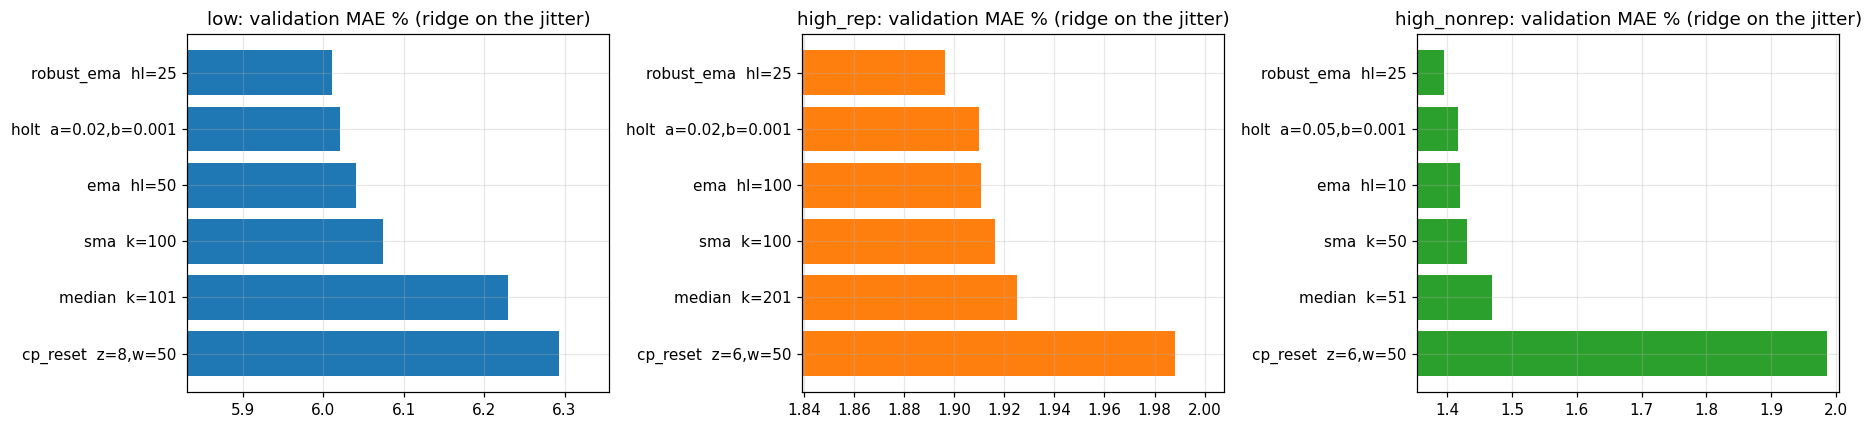

In [5]:
flt = pd.read_csv(R / "decompose_robust/filters.csv")
per = flt.groupby(["regime", "filter", "param"]).mean(numeric_only=True).reset_index()
best = per.loc[per.groupby(["regime", "filter"])["val_ridge_mae_pct"].idxmin()]
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, reg in zip(axes, REGIMES):
    b = best[best.regime == reg].sort_values("val_ridge_mae_pct")
    ax.barh(b["filter"] + "  " + b["param"], b["val_ridge_mae_pct"], color=REG_COL[reg])
    lo = b["val_ridge_mae_pct"].min(); ax.set_xlim(lo * 0.97, b["val_ridge_mae_pct"].max() * 1.01)
    ax.set_title(f"{reg}: validation MAE % (ridge on the jitter)"); ax.invert_yaxis()
fig.tight_layout()
best.sort_values(["regime", "val_ridge_mae_pct"])[["regime", "filter", "param", "val_ridge_mae_pct", "test_ridge_mae_pct",
                                                   "val_jitter_acf1", "val_corr_camera", "val_corr_lab"]].round(3)

**Reading.**
- With the robust preparation, the **outlier-robust EMA with a 25-shot half-life wins in all three regimes**, 1–5 %
  better than the trailing 50-shot mean used so far. Without the robust preparation the choice varied by regime
  (`results/decompose/summary.md`), another sign that outliers were driving it.
- Change-point reset is the worst here: the clean segments have few level changes.
- Plain EMA and Holt are close behind; the family matters less than handling outliers.

In [6]:
g = segs[5]
from decompose import causal, f_robust_ema, f_sma
lv_r = causal(lambda x: f_robust_ema(x, 25))(g["logy"], g["good"])
lv_s = causal(lambda x: f_sma(x, 50))(g["logy"], g["good"])
sl = slice(int(0.9 * g["n"]) - 400, int(0.9 * g["n"]) + 400)
idx = np.arange(g["n"])[sl]; good = g["good"][sl]
fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(idx[good], g["y"][sl][good], ".", ms=3, color="0.6", label="BCM (good shots)")
ax.plot(idx, np.exp(lv_s[sl]), label="trailing 50-shot mean")
ax.plot(idx, np.exp(lv_r[sl]), label="robust EMA, half-life 25")
ax.axvline(int(0.9 * g["n"]), color="k", ls="--", lw=0.8); ax.text(int(0.9 * g["n"]), ax.get_ylim()[1], " test", va="top")
ax.set_xlabel("shot (row)"); ax.set_ylabel("charge (nC)"); ax.set_title("seg 5: level estimates around the train/test boundary"); ax.legend()